# Compliance and security for vision models

### Key words

| Word | Meaning | Example |
|---|---|---|
| Safety | Protecting people from accidents | Alert when a worker has no helmet |
| Security | Protecting systems and places from attacks or unwanted access | Only genuine model files are loaded |
| Privacy | Protecting personal data | Faces and number plates are blurred |
| Compliance | Following laws, rules and licences | GDPR, licence terms |
| Pickle | Python's way to store objects in a file. Loading it can run code | A `.pt` file |
| SHA-256 fingerprint | A code computed from a file. One changed byte gives a different code | `9b09cc8b...` |
| Data minimisation | Storing only the data that is needed | Counts instead of video |
| Miss / false alarm | A real object not found / something found that is not there | A hidden car / a shadow called "car" |
| GDPR | The European law on personal data | Faces are personal data |
| EU AI Act | The European law on AI systems, with rules by risk level | Identifying people is strictly regulated |
| AGPL-3.0 | The Ultralytics licence: free for open projects | Closed products need a paid licence |

## 0. Setup
Run this cell once. Expected output: `True`.

In [1]:
import sys
print("Using this folder's uv environment:", ".venv" in sys.executable)

import glob, hashlib, os
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import requests
from ultralytics import YOLO, solutions

VIDEO = "video_example_1.mp4"
VEHICLES = [2, 3, 5, 7]  # car, motorcycle, bus, truck

cap = cv2.VideoCapture(VIDEO)
ok, FRAME = cap.read()  # the first frame
cap.release()
os.makedirs("outputs", exist_ok=True)

Using this folder's uv environment: True


## 1. Model security: verify that a model file is genuine

A `.pt` file is a Python **pickle**: loading it can run code. A modified file could be harmful.

**Rules**
1. Download models only from trusted sources.
2. Compare the file's **SHA-256 fingerprint** with the official one. One changed byte gives a different fingerprint.
3. Share models as **ONNX** when possible: an ONNX file stores the model as data, not as Python code.

Example: GitHub publishes the fingerprint of every Ultralytics model file.

In [2]:
def sha256(path):
    """Fingerprint of a file."""
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()


release = requests.get("https://api.github.com/repos/ultralytics/assets/releases/tags/v8.4.0", timeout=30).json()
official = {a["name"]: a["digest"].removeprefix("sha256:") for a in release["assets"] if a.get("digest")}

for name in sorted(glob.glob("*.pt") + glob.glob("*.ts")):
    if name in official:
        print(f"{name:22} genuine: {sha256(name) == official[name]}")
    else:
        print(f"{name:22} no official fingerprint found")

mobileclip2_b.ts       genuine: True
yolo26n-seg.pt         genuine: True
yolo26n.pt             genuine: True
yoloe-26n-seg-pf.pt    genuine: True
yoloe-26n-seg.pt       genuine: True


**What to observe:** every model file should print `genuine: True`.

## 2. Privacy: blur what should not be seen

Faces and number plates are personal data. Blurring them protects privacy by design.
Here the vehicles are blurred as an example. For people, use class `0` (person).

Ultralytics Solutions:  {'source': None, 'model': 'yolo26n.pt', 'classes': [2, 3, 5, 7], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': None, 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (20, 20), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': False, 'iou': 0.7, 'conf': 0.25, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 640, 'tracker': 'tracktrack.yaml', 'verbose': False, 'data': 'images'}


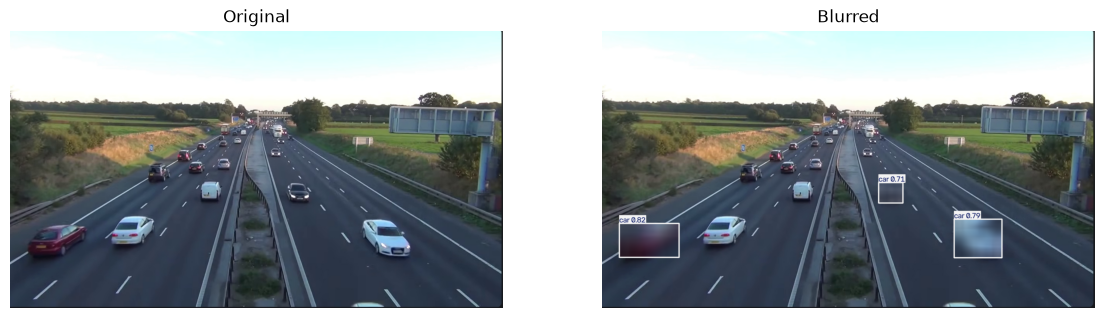

In [3]:
blurrer = solutions.ObjectBlurrer(model="yolo26n.pt", classes=VEHICLES, blur_ratio=0.5, show=False, verbose=False)
blurred = blurrer.process(FRAME.copy()).plot_im

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, image, title in zip(axes, [FRAME, blurred], ["Original", "Blurred"]):
    ax.imshow(image[:, :, ::-1])
    ax.set_title(title)
    ax.axis("off")
plt.show()

## 3. Data minimisation: store numbers, not video

Many uses only need numbers. Example: vehicles per second.
The video can then be deleted, and no personal data is stored.

In [4]:
model = YOLO("yolo26n.pt")
cap = cv2.VideoCapture(VIDEO)
fps = cap.get(cv2.CAP_PROP_FPS)
rows = []

for second in range(10):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(second * fps))  # one frame per second
    ok, frame = cap.read()
    count = len(model(frame, classes=VEHICLES, verbose=False)[0].boxes)
    rows.append({"second": second, "vehicles": count})
cap.release()

counts = pd.DataFrame(rows)
counts.to_csv("outputs/vehicle_counts.csv", index=False)  # only numbers are stored
counts.T

,0,1,2,3,4,5,6,7,8,9
second,0,1,2,3,4,5,6,7,8,9
vehicles,11,9,9,12,10,11,11,13,12,14


## 4. Errors: the confidence threshold trade-off

Every model makes two kinds of mistakes:
- **Miss:** a real object is not found.
- **False alarm:** something is found that is not there.

A **low** threshold gives fewer misses but more false alarms. A **high** threshold gives the opposite.
For this reason, a person should review important alerts.

In [5]:
rows = []
for conf in [0.1, 0.25, 0.5, 0.75]:
    found = len(model(FRAME, classes=VEHICLES, conf=conf, verbose=False)[0].boxes)
    rows.append({"confidence threshold": conf, "vehicles found": found})
pd.DataFrame(rows)

,confidence threshold,vehicles found
0,0.10,16
1,0.25,11
2,0.50,7
3,0.75,2


**What to observe:** the number of vehicles changes with the threshold. The right value depends on the cost of each mistake.
Example: a safety alarm usually prefers a false alarm over a miss.

## 5. Licences and laws

| Topic | Key point |
|---|---|
| Ultralytics licence | **AGPL-3.0**: free for open projects. A closed commercial product requires an Enterprise licence. |
| Training data | Datasets have their own licence terms. Check them before commercial use. |
| GDPR (Europe) | Faces and number plates are personal data. A legal basis is required. |
| EU AI Act | Rules depend on the risk level. Identifying people is strictly regulated. |

## 6. Checklist

| Area | Check |
|---|---|
| Model files | Official source, fingerprint verified, versions pinned (`uv.lock`) |
| Privacy | Faces and plates blurred, or not recorded |
| Storage | Counts stored instead of video when possible |
| Errors | Threshold chosen on purpose, alerts reviewed by a person |
| Legal | Licence checked, local privacy rules followed |